# Step 1: Nuclei segmentation with StarDist

> **⚠️ Environment:** run this notebook in the separate **`stardist`** environment, **not** the main `hiNiche` environment.
> StarDist depends on TensorFlow, which requires `numpy<2` and is incompatible with the RAPIDS / PyTorch stack used in steps 2 and 3.
>
> ```bash
> conda env create -f environment_stardist.yml
> conda activate stardist
> python -m ipykernel install --user --name stardist
> ```
>
> Then select the `stardist` kernel for this notebook.

This notebook segments nuclei on the full-resolution H&E image with the pretrained StarDist `2D_versatile_he` model and saves the nuclei label mask as a sparse `.npz` file. The output is used as `segmentation_mask.npz` in step 3.

## 1. Load and normalize the H&E image

Set `hd_fullres_img_btf_path` to the full-resolution H&E image (`.btf`) of your sample. The image is read lazily as a zarr store and percentile-normalized to [0, 1].

In [ ]:
import tifffile as tiff
import zarr
import matplotlib.pyplot as plt
import scipy.spatial
import scipy.sparse
import scipy.stats
import scanpy as sc
import numpy as np

def normalize(img):
    '''
    Extremely naive reimplementation of default ``cbsdeep.utils.normalize()`` 
    percentile normalisation, with a lower RAM footprint than the original.
    
    Input
    -----
    img : ``numpy.array``
        Numpy array image to normalize
    '''
    eps = 1e-20
    mi = np.percentile(img,3)
    ma = np.percentile(img,99.8)
    norm = (img - mi) / ( ma - mi + eps )
    norm[norm < 0] = 0
    norm[norm > 1] = 1
    return norm

#hd_data_square_002um_path = '/Users/weihangzhang/Documents/Project/Spatial_data/HD/Mouse_Brain/binned_outputs/square_002um/' # shall contain filtered_feature_bc_matrix.h5 
hd_fullres_img_btf_path = "/Users/weihangzhang/Documents/Project/Spatial_data/HD/Breast_Cancer3/Visium_HD_Human_Breast_Cancer_Fixed_Frozen_tissue_image.btf"

with tiff.TiffFile(hd_fullres_img_btf_path) as tif:
    print(tif.series)
    store = tif.series[0].aszarr()   # lazy store，不读全图
    
z = zarr.open(store, mode="r")
z = normalize(z)



[<tifffile.TiffPageSeries 0 ome>]


## 2. Visualize the normalized image

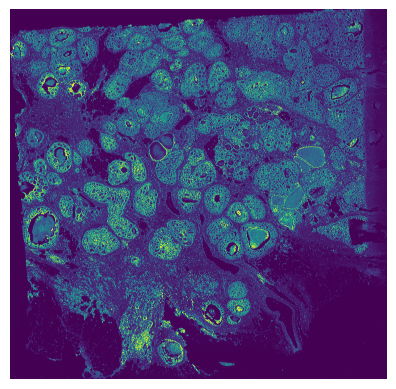

In [ ]:
plt.imshow(z)
plt.axis("off")
plt.show()

## 3. Segment nuclei with StarDist

`predict_instances_big` tiles the image automatically. `prob_thresh` and `nms_thresh` control detection sensitivity and overlap suppression.

In [ ]:
from stardist.models import StarDist2D
#load and percentile normalize image, following stardist demo protocol
#turn it to np.float16 pre normalisation to keep RAM footprint minimal

stardist_model = "2D_versatile_he"
#use pretrained stardist model
model = StarDist2D.from_pretrained(stardist_model)
#will need to specify axes shortly, which are model dependent
if stardist_model == "2D_versatile_he":
    #3D image, got the axes YXC from the H&E model config.json
    model_axes = "YXC"
elif stardist_model == "2D_versatile_fluo":
    #2D image, got the axes YX from logic and trying and it working
    model_axes = "YX"
#run predict_instances_big() to perform automated tiling of the input
#this is less parameterised than predict_instances, needed to pass axes too
#pass any other **kwargs to the thing, passing them on internally
#in practice this is going to be prob_thresh
labels, polys = model.predict_instances_big(z, 
                                        axes=model_axes, 
                                        block_size=4096, 
                                        min_overlap=128, 
                                        context=128,
                                        prob_thresh=0.01,
                                        nms_thresh = 0.001,
                                        )
#store resulting labels as sparse matrix NPZ - super efficient space wise
labels_sparse = scipy.sparse.csr_matrix(labels)
print("Found "+str(len(np.unique(labels_sparse.data)))+" objects")

Found model '2D_versatile_he' for 'StarDist2D'.
Loading network weights from 'weights_best.h5'.
Loading thresholds from 'thresholds.json'.
Using default values: prob_thresh=0.692478, nms_thresh=0.3.
effective: block_size=(4096, 4096, 3), min_overlap=(128, 128, 0), context=(128, 128, 0)


100%|██████████| 132/132 [23:20<00:00, 10.61s/it]


Found 788559 objects


## 4. Save the segmentation mask

The label image is stored as a sparse matrix. Save it as `DATA/<SAMPLE>/segmentation_mask.npz` so that step 3 can load it.

In [15]:
scipy.sparse.save_npz("/Users/weihangzhang/Documents/Project/Spatial_data/HD/Breast_Cancer_DCIS1/labels_sparse_prob_0.01_0.001.npz", labels_sparse)